# 02 · Your first model call, as a one-node graph
Level L1 · Part 1 · core · ~20 min · builds on 01

## Goal
Make a model call through the course's shared setup, read the reply, its usage and its cost, then stream the same answer as
it is written. The call is a node in a LangGraph graph, so every later lesson starts from the same shape.

## Why it matters
A model call is a request with three parts: the instructions, the message and the settings. Without a library, every
script writes its own request, reads the reply out of a nested structure, and works out the cost by hand. A second script
copies the code, and the copies drift.

| Without a library | With the shared setup and a graph |
|---|---|
| Each script builds its own request and reads its own reply | One call through `get_llm().invoke`, and one reply object |
| The cost is worked out by hand, and often forgotten | The usage the reply already carries gives the cost |

**What it makes easy:** one place for the model, the keys and the settings. **When you don't need it:** a one-off question
in a notebook cell; the rest of this course needs the graph.

## The idea
A **graph** is nodes and edges. A **node** is a function; an **edge** says what runs next. The state is the record every
node reads. Here the graph has one node, `call_model`, and it reads the messages and returns the model's reply. The reply is
added to the messages. That is all a model call is, inside an agent.

The model keeps no memory between calls: it sees only the messages it is sent. So the graph resends the whole messages list
on each call, and that is how a later call knows what came before.

Analogy: a hotel concierge with one job. The guest's message goes in, the answer comes out, and the receipt (the usage) comes
with it.

## Picture
Amber means the node calls the model. The graph below is drawn from the compiled app in Step 2.

## Step by step

**Step 1 · setup (one model for the lesson).** `llm_setup.get_llm()` is the course's shared setup: it reads the key from
`.env`, so nothing is typed here. `llm_replay` saves the answers the first time, so later runs need no key. The model is
the course's pinned model, set in one place.

In [1]:
import sys; sys.path.insert(0, "../../..")  # the topic folder: llm_setup.py, graph_view.py and tut_env.py live there

import llm_replay  # course helper: records and replays model calls (not part of LangGraph)
llm_replay.start("02_first-model-call")

from typing import Annotated
from langchain_core.messages import AnyMessage, HumanMessage
from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import add_messages
from typing_extensions import TypedDict
from llm_setup import get_llm  # course helper: the shared model setup (one model, temperature 0)
from graph_view import show_graph  # course helper: draws the graph as a picture

llm = get_llm()
PRICE_IN, PRICE_OUT = 0.25, 1.50  # USD per 1M tokens, as checked for lesson 02 on 2026-10-20

LLM mode: replay (02_first-model-call.yaml)


Gemini on Vertex AI · API key loaded: True


**Step 2 · the state and the one node (no model call yet).** `add_messages` is a reducer: a node's reply is appended to the
list, and the older messages are kept. The node itself is one line: call the model with the messages so far. `show_graph`
(the course helper from Step 1) draws the compiled graph in the Picture above.

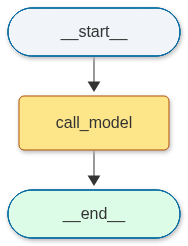

In [2]:
class ChatState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]


def call_model(state: ChatState) -> dict:
    reply = llm.invoke(state["messages"])  # one model call
    return {"messages": [reply]}


g = StateGraph(ChatState)
g.add_node("call_model", call_model)
g.add_edge(START, "call_model")
g.add_edge("call_model", END)
app = g.compile()
show_graph(app, model_nodes=("call_model",))

**Step 3 · run it (1 model call).** `invoke` runs the graph once. The reply is the last message. Its `usage_metadata` counts
the tokens the model read (`input_tokens`) and wrote (`output_tokens`), and the reply carries them itself, so no second
request is needed. The extra `total_tokens` key is the sum of the two. `input_token_details` (here `cache_read`, the tokens
served from a cache) can be ignored for now.

In [3]:
question = "A customer writes: 'My order arrived broken. What do I do?' Answer in one sentence."
result = app.invoke({"messages": [HumanMessage(content=question)]})
reply = result["messages"][-1]
print("answer:", reply.text)
print("usage:", reply.usage_metadata)

answer: A model call is a request sent to an artificial intelligence model to process an input and generate a corresponding output based on its training.
usage: {'input_tokens': 10, 'output_tokens': 26, 'total_tokens': 36, 'input_token_details': {'cache_read': 0}}


**Step 4 · the cost, from the usage (no call).** The price is per million tokens. Input and output are priced differently,
so the cost is two terms added together.

In [4]:
def cost_usd(usage: dict) -> float:
    return (usage["input_tokens"] * PRICE_IN + usage["output_tokens"] * PRICE_OUT) / 1_000_000


print(f"this call cost ${cost_usd(reply.usage_metadata):.6f}")

this call cost $0.000041


**Step 5 · stream the same node (1 model call).** `stream_mode="messages"` yields each piece of text (a chunk) as the model
writes it. Each chunk comes with `meta`, a small dict about the run; here we use one key, `meta["langgraph_node"]`, which
names the node that wrote the chunk, so we print only the chunks from `call_model`. The graph and the node do not change;
only the way the run reports its progress does.

In [5]:
print("streamed: ", end="")
for chunk, meta in app.stream({"messages": [HumanMessage(content="Write a one-sentence greeting for a customer who just opened our support chat.")]},
                              stream_mode="messages"):
    if meta.get("langgraph_node") == "call_model" and chunk.text:
        print(chunk.text, end="", flush=True)
print()
llm_replay.stop()  # the last model call of this lesson

streamed: One

 primary reason to stream a model answer is to **reduce perceived latency** for the user.

By

 displaying the text as it is being generated, the user can begin reading the response immediately rather than waiting for the entire output to be processed

. This significantly improves the user experience, making the interaction feel faster, more responsive, and more conversational.

## At work
- Teams keep one model setup for the whole product: the key, the model name and the retry rules live in one place. A model
  change then touches one file → lesson 33 (cost and latency).
- The usage in every reply is the bill. Teams log it per request, so cost is measured, not guessed → lesson 25 (observability).
- Model APIs answer 429 (rate limit: too many requests) and 503 (the service is busy). Production code retries those with
  exponential backoff and jitter, and sets a timeout on every call → lesson 32 (retries, timeouts and rate limits).
- Streaming makes a slow answer feel fast, because the first words arrive early. It is the same call, reported as it runs.

## What just happened
- Step 3 printed one answer and its usage: 20 input tokens and 24 output tokens.
- Step 4 turned those counts into $0.000041 for that one call.
- Step 5 streamed its answer in chunks. In the replay each chunk shows on its own line; joined together, they are the
  full text. The prompt asked for one sentence, but the model offered several greetings: a prompt is a request, not a
  guarantee, so check the output.
- The notebook made two model calls in total: Step 3 and Step 5.

## Common mistakes
1. **Treating the reply as a string.** The reply is a message. Read `reply.text`, and check `reply.usage_metadata` for the
   cost. The cell below uses a hand-made message (no model call) and shows the error you get when you call a string method
   on it.

In [6]:
from langchain_core.messages import AIMessage

sample = AIMessage(content="A model call is one request.")  # built by hand: no model call
try:
    sample.upper()  # a message is not a string, so this fails
except AttributeError as e:
    print(type(e).__name__, str(e).splitlines()[0])

AttributeError 'AIMessage' object has no attribute 'upper'


2. **Forgetting that the input price is not the output price.** The cost helper prices them separately; a single average
   hides which side grows.

3. **Printing the key.** The setup reads it from `.env` and prints only whether it is loaded. Never print the value.

## Try it
Write `cost_for_calls(usages)` that takes a list of usage dicts and returns the total cost in dollars, using `cost_usd`.
No model call is needed. Test it on two usages: 1,000 input and 200 output tokens, then 500 input and 50 output tokens.

In [7]:
# your code here

**Answer** — try it first, then expand the hidden cell below.

In [8]:
def cost_for_calls(usages: list[dict]) -> float:
    return sum(cost_usd(u) for u in usages)


print(f"${cost_for_calls([{'input_tokens': 1000, 'output_tokens': 200}, {'input_tokens': 500, 'output_tokens': 50}]):.6f}")

$0.000750


## Key terms
- **Graph** — nodes and edges that run in a set order; the shape every agent in this course takes.
- **Node** — a function in the graph that reads the state and returns an update.
- **Edge** — a link that says which node runs next.
- **State** — the record every node reads, and the updates are merged into.
- **Reducer** — the rule that merges a node's update into the state; `add_messages` appends new messages.
- **Usage** — the input and output token counts a reply carries (`usage_metadata`); the basis of the cost.
- **Streaming** — receiving the reply in chunks as it is written (`stream_mode="messages"`).

## Recap
- A model call is a node: it reads the state, calls the model once, and returns the reply as a new message.
- The reply carries its usage, so the cost comes from the reply, not from a second request.
- The same node streams its answer with `stream_mode="messages"`.
- Every later lesson uses this setup, so the key and the model are set in one place.

**Interview:** "What does one model call cost, and where do you read it?" Strong answer: "Input and output tokens, each with its
own price. The reply carries the counts in its usage, so I log cost per request from the response itself."